# Experiment 8 :: Abstractive Text Summarization with mT5 and mBART (Hindi XL-Sum)

- 8.1 Load a chunk of the **Hindi** subset of XL-Sum
- 8.2 Summarization with **mT5** (`csebuetnlp/mT5_multilingual_XLSum`)
- 8.3 Summarization with **mBART-50** (`mskayacioglu/mbart50-xlsum`)
- 8.4 Evaluation with **ROUGE-1, ROUGE-2, ROUGE-L** and **mBERT score** (BERTScore with `bert-base-multilingual-cased`)
- 8.5 Comparative analysis

Both checkpoints are the pretrained models already fine-tuned for XL-Sum summarization. They are tested on unseen articles from the Hindi **test** split.

In [1]:
%pip install -q pandas numpy matplotlib seaborn torch transformers sentencepiece protobuf huggingface_hub pyarrow rouge_score bert_score tabulate

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, gc, json, time, tarfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

torch.manual_seed(42)
np.random.seed(42)

device = 'mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

N_SAMPLES = 200        # chunk of the Hindi test set (increase if you have time)
BATCH_SIZE = 8
MAX_INPUT_LEN = 512

Device: cuda


## 8.1 Dataset — Hindi subset of XL-Sum

In [3]:
from huggingface_hub import hf_hub_download, list_repo_files

REPO = 'csebuetnlp/xlsum'
LANG = 'hindi'
files = list_repo_files(REPO, repo_type='dataset')

if f'{LANG}/xlsum-test.parquet' in files:
    # newer parquet version of the dataset
    test_path = hf_hub_download(REPO, f'{LANG}/xlsum-test.parquet', repo_type='dataset')
    full_test = pd.read_parquet(test_path)
else:
    # original release: one .tar.bz2 archive per language with train/val/test .jsonl files
    tar_name = next(f for f in files if f.startswith(f'data/{LANG}_XLSum'))
    tar_path = hf_hub_download(REPO, tar_name, repo_type='dataset')
    with tarfile.open(tar_path) as tar:
        member = next(m for m in tar.getmembers() if m.name.endswith('test.jsonl'))
        lines = tar.extractfile(member).read().decode('utf-8').splitlines()
    full_test = pd.DataFrame([json.loads(l) for l in lines])

print('Full Hindi test set:', full_test.shape)
df = full_test.sample(N_SAMPLES, random_state=42).reset_index(drop=True)
print('Chunk used for this experiment:', df.shape)
df[['title', 'summary', 'text']].head()

data/hindi_XLSum_v2.0.tar.bz2: reconstructing file:   0%|          |  0.00B / 82.3MB            

data/hindi_XLSum_v2.0.tar.bz2: downloading bytes:           |  0.00B            

C:\Users\rudra\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\rudra\.cache\huggingface\hub\datasets--csebuetnlp--xlsum. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Full Hindi test set: (8847, 5)
Chunk used for this experiment: (200, 5)


,title,summary,text
0,बीआर चोपड़ा की यादगार फ़िल्मों का विशेष उत्सव,भारतीय फ़िल्म इतिहास में फ़िल्मकार बीआर चोपड़ा...,शुक्रवार शाम को शुरु हुए फ़ेस्टिवल में इंसाफ़ ...
1,तालेबान ने सैकड़ों क़ैदियों को छुड़ाया,अफ़ग़ानिस्तान के कंधार में तालेबान चरमपंथियों ...,कंधार के प्रांतीय सभा के अध्यक्ष और राष्ट्रपति...
2,रिकॉर्ड की ख़ातिर हाथ-पैर बांध कर की तैराकी,गिनीज़ वर्ल्ड रिकॉर्ड में अपना नाम दर्ज कराने ...,ख़बरों के मुताबिक़ जेन पेत्कोव को मैसेडोनिया क...
3,अमरीका ने जी-4 का प्रस्ताव ठुकराया,अमरीका ने जी-4 देशों द्वारा सुरक्षा परिषद के व...,"जी-4 में भारत के साथ-साथ ब्राज़ील, जापान और जर..."
4,मैं खतरनाक स्थिति में हूँ: सलमान खान,तीन लगातार बड़ी हिट फिल्में देने के बाद सलमान ...,फिल्म एक था टाइगर में सलमान खान और कटरीना कैफ ...


In [4]:
df['text_words'] = df['text'].str.split().str.len()
df['summary_words'] = df['summary'].str.split().str.len()
print(df[['text_words', 'summary_words']].describe().round(1))

print('\nSample article:\n', df['text'][0][:500], '...')
print('\nReference summary:\n', df['summary'][0])

       text_words  summary_words
count       200.0          200.0
mean        458.9           27.5
std         272.1            8.1
min         125.0            9.0
25%         258.0           21.0
50%         364.0           27.5
75%         617.2           32.2
max        1264.0           50.0

Sample article:
 शुक्रवार शाम को शुरु हुए फ़ेस्टिवल में इंसाफ़ का तराज़ू फ़िल्म दिखाई गई. उत्सव के दौरान छोटी सी बात, नया दौर और वक़्त जैसी क्लासिक फ़िल्में देखने को मिलेंगी. खराब सेहत के कारण बीआर चोपड़ा ख़ुद समारोह में शामिल नहीं हो सके.फ़िल्मोत्सव का उदघाटन बीआर चोपड़ा के भाई और मशहूर फ़िल्मकार यश चोपड़ा ने किया. उन्होंने कहा, "मेरे भाई ने अपने हिसाब से फ़िल्में बनाईं- वो भी ऐसे समय में जब लोग ऐसी फ़िल्मों की व्यावसायिक सफलता को लेकर आशंकित रहते थे क्योंकि ये फ़िल्में कुछ हटकर होती थीं, उस समय जिस तरह की कहान ...

Reference summary:
 भारतीय फ़िल्म इतिहास में फ़िल्मकार बीआर चोपड़ा का नाम बड़ा अदब से लिया जाता है. उनके 94वें जन्मदिन के मौके पर दिल्ली में बीआर चोपड़ा की फ़िल्मों का विशेष उत्सव

### Common helpers — batched generation and evaluation metrics

In [5]:
WHITESPACE_HANDLER = lambda k: re.sub(r'\s+', ' ', re.sub(r'\n+', ' ', k.strip()))

def summarize(model, tokenizer, texts, gen_kwargs):
    summaries = []
    for i in range(0, len(texts), BATCH_SIZE):
        batch = [WHITESPACE_HANDLER(t) for t in texts[i:i + BATCH_SIZE]]
        inputs = tokenizer(batch, return_tensors='pt', padding=True, truncation=True,
                           max_length=MAX_INPUT_LEN).to(device)
        with torch.no_grad():
            output_ids = model.generate(**inputs, **gen_kwargs)
        summaries += tokenizer.batch_decode(output_ids, skip_special_tokens=True,
                                            clean_up_tokenization_spaces=False)
        print(f'  {min(i + BATCH_SIZE, len(texts))}/{len(texts)} articles summarized', end='\r')
    print()
    return summaries

def free_memory():
    gc.collect()
    if device == 'cuda': torch.cuda.empty_cache()
    if device == 'mps': torch.mps.empty_cache()

**ROUGE for Hindi:** the default `rouge_score` tokenizer keeps only English letters and digits, so every Hindi word would be dropped and all scores would be 0. A custom tokenizer that keeps Devanagari characters (and drops the `।` full stop) is used instead.

In [6]:
from rouge_score import rouge_scorer

class HindiTokenizer:
    def tokenize(self, text):
        text = text.replace('।', ' ').replace('॥', ' ')
        return re.findall(r'[\u0900-\u097F\w]+', text.lower())

scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], tokenizer=HindiTokenizer())

def rouge_scores(predictions, references):
    rows = [scorer.score(ref, pred) for pred, ref in zip(predictions, references)]
    return pd.DataFrame({
        'ROUGE-1': [r['rouge1'].fmeasure for r in rows],
        'ROUGE-2': [r['rouge2'].fmeasure for r in rows],
        'ROUGE-L': [r['rougeL'].fmeasure for r in rows],
    })

print(HindiTokenizer().tokenize('भारत की राजधानी नई दिल्ली है। यह एक बड़ा शहर है।'))

['भारत', 'की', 'राजधानी', 'नई', 'दिल्ली', 'है', 'यह', 'एक', 'बड़ा', 'शहर', 'है']


In [7]:
from bert_score import score as bert_score

def mbert_scores(predictions, references):
    P, R, F = bert_score(predictions, references, model_type='bert-base-multilingual-cased',
                         device=device, batch_size=16, verbose=False)
    return pd.DataFrame({'mBERT-P': P.numpy(), 'mBERT-R': R.numpy(), 'mBERT-F1': F.numpy()})

references = df['summary'].tolist()
articles = df['text'].tolist()
scores, predictions, timings = {}, {}, {}

## 8.2 mT5 — `csebuetnlp/mT5_multilingual_XLSum`
mT5-base (~580M parameters) pretrained on the multilingual mC4 corpus (101 languages) and fine-tuned on all 45 XL-Sum languages. Text-to-text model with a SentencePiece vocabulary of 250K tokens.

In [8]:
mt5_name = 'csebuetnlp/mT5_multilingual_XLSum'
mt5_tokenizer = AutoTokenizer.from_pretrained(mt5_name)
mt5_model = AutoModelForSeq2SeqLM.from_pretrained(mt5_name).to(device).eval()
print('Parameters:', f'{sum(p.numel() for p in mt5_model.parameters()) / 1e6:.0f}M')

mt5_gen = dict(max_length=84, num_beams=4, no_repeat_ngram_size=2)

start = time.time()
predictions['mT5'] = summarize(mt5_model, mt5_tokenizer, articles, mt5_gen)
timings['mT5'] = time.time() - start
print(f'Generation time: {timings["mT5"]:.0f}s')

del mt5_model
free_memory()

config.json:   0%|          | 0.00/730 [00:00<?, ?B/s]

C:\Users\rudra\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\rudra\.cache\huggingface\hub\models--csebuetnlp--mT5_multilingual_XLSum. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spiece.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

... (3 outputs left out)

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


model.safetensors: reconstructing file:   0%|          |  0.00B / 2.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Parameters: 582M
  200/200 articles summarized
Generation time: 86s


In [9]:
scores['mT5'] = pd.concat([rouge_scores(predictions['mT5'], references),
                           mbert_scores(predictions['mT5'], references)], axis=1)
scores['mT5'].mean().round(4)

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

C:\Users\rudra\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\rudra\.cache\huggingface\hub\models--bert-base-multilingual-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ROUGE-1     0.3613
ROUGE-2     0.1591
ROUGE-L     0.3033
mBERT-P     0.7879
mBERT-R     0.7520
mBERT-F1    0.7689
dtype: float64

## 8.3 mBART-50 — `mskayacioglu/mbart50-xlsum`
mBART-large-50 (~610M parameters), a denoising auto-encoder pretrained on 50 languages, fine-tuned on XL-Sum (including Hindi). mBART needs the language code `hi_IN` for both the source text and the generated summary (`forced_bos_token_id`).

In [10]:
mbart_name = 'mskayacioglu/mbart50-xlsum'
mbart_tokenizer = AutoTokenizer.from_pretrained(mbart_name, src_lang='hi_IN', tgt_lang='hi_IN')
mbart_model = AutoModelForSeq2SeqLM.from_pretrained(mbart_name).to(device).eval()
print('Parameters:', f'{sum(p.numel() for p in mbart_model.parameters()) / 1e6:.0f}M')

mbart_gen = dict(forced_bos_token_id=mbart_tokenizer.convert_tokens_to_ids('hi_IN'),
                 max_length=90, min_length=24, num_beams=5, length_penalty=1.1,
                 no_repeat_ngram_size=3, repetition_penalty=1.05, early_stopping=True)

start = time.time()
predictions['mBART'] = summarize(mbart_model, mbart_tokenizer, articles, mbart_gen)
timings['mBART'] = time.time() - start
print(f'Generation time: {timings["mBART"]:.0f}s')

del mbart_model
free_memory()

config.json:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

C:\Users\rudra\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\rudra\.cache\huggingface\hub\models--mskayacioglu--mbart50-xlsum. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/516 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/256 [00:00<?, ?B/s]

Parameters: 611M
  200/200 articles summarized
Generation time: 106s


In [11]:
scores['mBART'] = pd.concat([rouge_scores(predictions['mBART'], references),
                             mbert_scores(predictions['mBART'], references)], axis=1)
scores['mBART'].mean().round(4)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ROUGE-1     0.3447
ROUGE-2     0.1360
ROUGE-L     0.2838
mBERT-P     0.7688
mBERT-R     0.7520
mBERT-F1    0.7598
dtype: float64

## 8.4 Sample outputs

In [12]:
for i in range(3):
    print(f'===== Article {i + 1} =====')
    print('Article   :', WHITESPACE_HANDLER(articles[i])[:300], '...')
    print('Reference :', references[i])
    print('mT5       :', predictions['mT5'][i])
    print('mBART     :', predictions['mBART'][i])
    print()

===== Article 1 =====
Article   : शुक्रवार शाम को शुरु हुए फ़ेस्टिवल में इंसाफ़ का तराज़ू फ़िल्म दिखाई गई. उत्सव के दौरान छोटी सी बात, नया दौर और वक़्त जैसी क्लासिक फ़िल्में देखने को मिलेंगी. खराब सेहत के कारण बीआर चोपड़ा ख़ुद समारोह में शामिल नहीं हो सके.फ़िल्मोत्सव का उदघाटन बीआर चोपड़ा के भाई और मशहूर फ़िल्मकार यश चोपड़ा ने किया. ...
Reference : भारतीय फ़िल्म इतिहास में फ़िल्मकार बीआर चोपड़ा का नाम बड़ा अदब से लिया जाता है. उनके 94वें जन्मदिन के मौके पर दिल्ली में बीआर चोपड़ा की फ़िल्मों का विशेष उत्सव मनाया जा रहा है.
mT5       : मशहूर फ़िल्मकार बीआर चोपड़ा के मुंबई में हुए फ़ेस्टिवल का उदघाटन किया गया है.
mBART     : हिंदी फ़िल्मों के जाने-माने निर्देशक बीआर चोपड़ा के जीवन पर आधारित फ़िल्म उत्सव का उदघाटन किया गया है.

===== Article 2 =====
Article   : कंधार के प्रांतीय सभा के अध्यक्ष और राष्ट्रपति हामिद करज़ई के भाई वली करज़ई ने बीबीसी को बताया कि उस समय जेल में एक हज़ार क़ैदी थे और सभी निकल भागे हैं. माना जाता है कि इन क़ैदियों में से 350 तालेबान थे. इस हमले में कई सुरक्षाकर्मिय

## 8.5 Comparative analysis

In [13]:
comparison = pd.DataFrame({m: s.mean() for m, s in scores.items()}).T
comparison['Avg summary length (words)'] = [np.mean([len(p.split()) for p in predictions[m]]) for m in comparison.index]
comparison['Generation time (s)'] = [timings[m] for m in comparison.index]
comparison.loc['Reference', 'Avg summary length (words)'] = df['summary_words'].mean()
comparison.round(4)

,ROUGE-1,ROUGE-2,ROUGE-L,mBERT-P,mBERT-R,mBERT-F1,Avg summary length (words),Generation time (s)
mT5,0.3613,0.1591,0.3033,0.7879,0.752,0.7689,18.670,86.3977
mBART,0.3447,0.1360,0.2838,0.7688,0.752,0.7598,23.795,105.8546
Reference,NaN,NaN,NaN,NaN,NaN,NaN,27.460,NaN


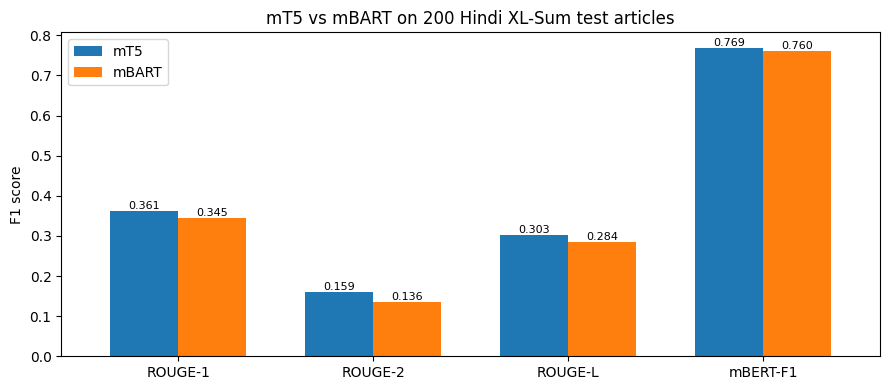

In [14]:
metrics = ['ROUGE-1', 'ROUGE-2', 'ROUGE-L', 'mBERT-F1']
ax = comparison.loc[['mT5', 'mBART'], metrics].T.plot(kind='bar', figsize=(9, 4), rot=0, width=0.7)
ax.set_title(f'mT5 vs mBART on {N_SAMPLES} Hindi XL-Sum test articles')
ax.set_ylabel('F1 score')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8)
plt.tight_layout()
plt.show()

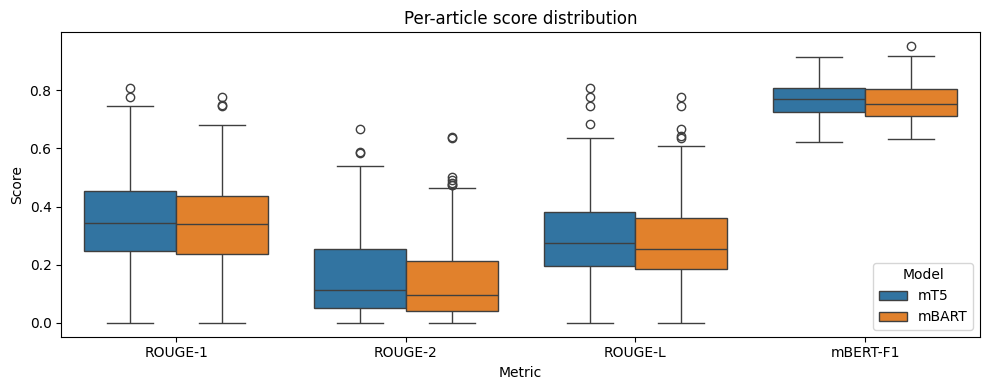

In [15]:
long_scores = pd.concat([s[['ROUGE-1', 'ROUGE-2', 'ROUGE-L', 'mBERT-F1']].assign(Model=m)
                         for m, s in scores.items()]).melt(id_vars='Model', var_name='Metric', value_name='Score')
plt.figure(figsize=(10, 4))
sns.boxplot(data=long_scores, x='Metric', y='Score', hue='Model')
plt.title('Per-article score distribution')
plt.tight_layout()
plt.show()

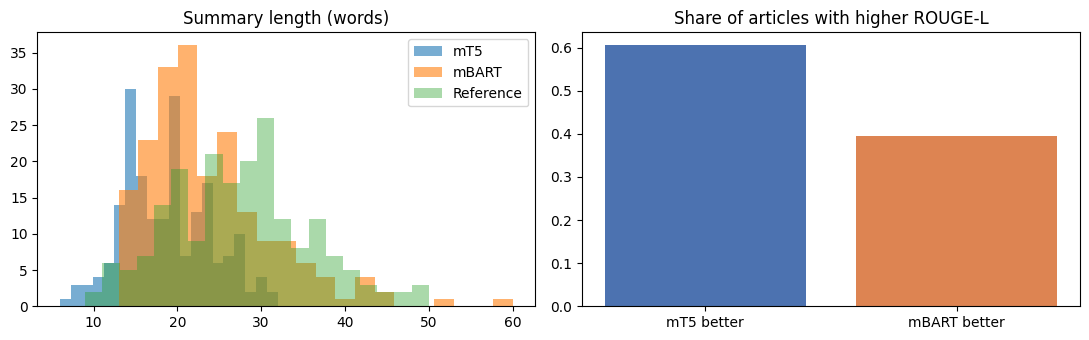

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for m in predictions:
    ax[0].hist([len(p.split()) for p in predictions[m]], bins=20, alpha=0.6, label=m)
ax[0].hist(df['summary_words'], bins=20, alpha=0.4, label='Reference')
ax[0].set_title('Summary length (words)'); ax[0].legend()

wins = (scores['mBART']['ROUGE-L'] > scores['mT5']['ROUGE-L']).mean()
ax[1].bar(['mT5 better', 'mBART better'], [1 - wins, wins], color=['#4C72B0', '#DD8452'])
ax[1].set_title('Share of articles with higher ROUGE-L')
plt.tight_layout()
plt.show()

In [17]:
best = comparison.loc[['mT5', 'mBART'], 'ROUGE-L'].idxmax()
print('Best model by ROUGE-L:', best)
print('Best model by mBERT-F1:', comparison.loc[['mT5', 'mBART'], 'mBERT-F1'].idxmax())

# Results table in Markdown (to paste into the README)
print()
print(comparison.loc[['mT5', 'mBART'], ['ROUGE-1', 'ROUGE-2', 'ROUGE-L', 'mBERT-P', 'mBERT-R', 'mBERT-F1',
                                        'Avg summary length (words)', 'Generation time (s)']].round(4).to_markdown())

Best model by ROUGE-L: mT5
Best model by mBERT-F1: mT5

|       |   ROUGE-1 |   ROUGE-2 |   ROUGE-L |   mBERT-P |   mBERT-R |   mBERT-F1 |   Avg summary length (words) |   Generation time (s) |
|:------|----------:|----------:|----------:|----------:|----------:|-----------:|-----------------------------:|----------------------:|
| mT5   |    0.3613 |    0.1591 |    0.3033 |    0.7879 |     0.752 |     0.7689 |                       18.67  |               86.3977 |
| mBART |    0.3447 |    0.136  |    0.2838 |    0.7688 |     0.752 |     0.7598 |                       23.795 |              105.855  |
